# Reading **RiverFlow2D** meshes with `pyramids-mesh`

**RiverFlow2D** (Hydronia) is a 2D river/flood model. Its mesh is a single ASCII **`.FED`** file: a triangular grid with node coordinates and bed elevation, plus per-element roughness and initial-condition fields.

`pyramids-mesh` registers a `riverflow2d` driver keyed on the `.fed` suffix. It parses the file into one [`MeshDataset`](https://serapeum-org.github.io/pyramids/latest/) — nodes, the triangular connectivity, `node_z` bed elevation, and the element fields `manning_n`, `init_wse` and `min_erode_elev` — with no GIS or analysis of its own (ADR-0005).

By the end you will be able to read a `.FED`, inspect its variables, map them, and run the full pyramids geospatial toolkit on the result.

## 1. The `.FED` layout

A `.FED` is three blocks of whitespace-delimited text:

| line(s) | fields |
|---|---|
| header | `NELEM NNODES 5 5` (the last two are unused) |
| `NNODES` node lines | `IN  X  Y  ZB  INITWSE  MINERODELEV  BCTYPE  BCFILENAME` |
| `NELEM` element lines | `IE  N1 N2 N3  MANNINGN  ELZB  ELINITWSE  ELMINERODELEV  …` |

Ids are 1-based and consecutive; every element is a **counter-clockwise triangle**. The per-cell data lives on the *elements*, so `manning_n`, `init_wse` and `min_erode_elev` come back as **face** variables; `ZB` becomes the node-located `node_z`. Boundary conditions live in a companion `.TBA` file and are not read here.

## 2. Imports

`MeshDataset` is the object every driver returns. Importing from `pyramids` also puts its vendored GDAL/PROJ data in place, so nothing here is import-order sensitive — just import the names you use.

In [1]:
from pathlib import Path
from pyramids.netcdf.ugrid import MeshDataset
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

## 3. Locate the data

The sample lives in its own `examples/data/riverflow2d/` subfolder. It is an authored, license-clean synthetic channel (RiverFlow2D ships no openly-licensed `.FED`) built to the exact `.FED` layout — see the folder's `SOURCE.txt`. We pass a `pathlib.Path`, never a `str`.

In [2]:
DATA = Path("../../examples/data")
FED = DATA / "riverflow2d" / "channel.fed"
print(FED.name, '->', FED.resolve())

channel.fed -> C:\python-environments\worktrees\pyramids-mesh\riverflow2d-fed-reader\examples\data\riverflow2d\channel.fed


## 4. Read the file

We name the `driver` explicitly. The driver's only job is to parse the `.FED` and hand back a `MeshDataset`.

In [3]:
ds = MeshDataset.read_file(FED, driver="riverflow2d")
ds

C:\python-environments\pixi\envs\pyramids-mesh-6329545599298937347\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'deltares1d' (pyramids_mesh.drivers.river_hydraulics.deltares:DeltaresNetworkDriver) could not be loaded and was skipped: ImportError("cannot import name 'place_nodes_on_network' from 'pyramids.netcdf.ugrid' (C:\\python-environments\\pixi\\envs\\pyramids-mesh-6329545599298937347\\envs\\dev\\Lib\\site-packages\\pyramids\\netcdf\\ugrid\\__init__.py)")
  driver = _instantiate(entry_point)
C:\python-environments\pixi\envs\pyramids-mesh-6329545599298937347\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'dfsu' (pyramids_mesh.drivers.coastal_ocean.dhi:DfsuDriver) could not be loaded and was skipped: ModuleNotFoundError("No module named 'mikeio'")
  driver = _instantiate(entry_point)


MeshDataset(mesh='mesh2d', n_node=80, n_face=120, n_edge=0, variables=['manning_n', 'init_wse', 'min_erode_elev', 'node_z'])

cleopatra switches matplotlib to a headless backend on the first read; this one call hands the notebook the inline backend so the maps below embed.

In [4]:
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `MeshDataset` reports its size, CRS and the variables carried alongside the topology. `crs` is `None` because a `.FED` declares no projection authority — the coordinates are still real metres, just unlocated in world space.

In [5]:
print('nodes :', ds.n_node)
print('faces :', ds.n_face)
print('crs   :', ds.crs)
print('vars  :', ds.data_variable_names)
print('bounds:', ds.bounds)

nodes : 80
faces : 120
crs   : None
vars  : ['manning_n', 'init_wse', 'min_erode_elev', 'node_z']
bounds: (500000.0, 4500000.0, 500750.0, 4500100.0)


### Per-variable summary

`ds.summary()` returns a pandas `DataFrame`: one row per variable. Note `manning_n` takes two values (the channel vs floodplain zones) and `min_erode_elev` is partly the `-9999` sentinel (floodplain cells have no erodible floor).

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
manning_n,120,0.03000,0.07500,0.052500,0.022500
init_wse,120,0.00000,9.50000,2.533333,4.201058
min_erode_elev,60,5.33333,8.46667,6.900000,0.874961
node_z,80,7.00000,11.60000,9.460000,1.099272


The driver also stamps provenance into `global_attributes`, so a converted dataset can be traced back to the format it came from.

In [7]:
ds.global_attributes

{'source': 'RiverFlow2D .FED'}

## 6. The `Mesh2d` geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the face-node connectivity. For a `.FED` the connectivity width is **3** — pure triangles — which is why the triangle-only operations below apply (unlike a mixed tri/quad mesh).

In [8]:
m = ds.mesh
print('node_x shape       :', m.node_x.shape)
print('connectivity shape :', m.face_node_connectivity.data.shape)
print('face_areas shape   :', m.face_areas.shape)
print('first face areas   :', m.face_areas[:3])

node_x shape       : (80,)
connectivity shape : (120, 3)
face_areas shape   : (120,)
first face areas   : [625. 625. 625.]


## 7. Wireframe — the mesh skeleton

`plot_outline()` draws every face edge with no data colouring: the fastest way to eyeball the triangulation and extent.

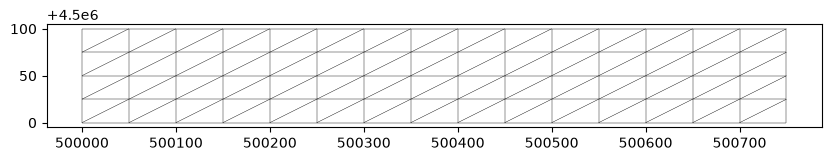

In [9]:
_g = ds.plot_outline()

## 8. Roughness map — `manning_n`

The headline field for a hydraulic model is **Manning's n**, per element. The two bands are the low-roughness channel threading between the rougher floodplain — exactly the zoning the solver runs against.

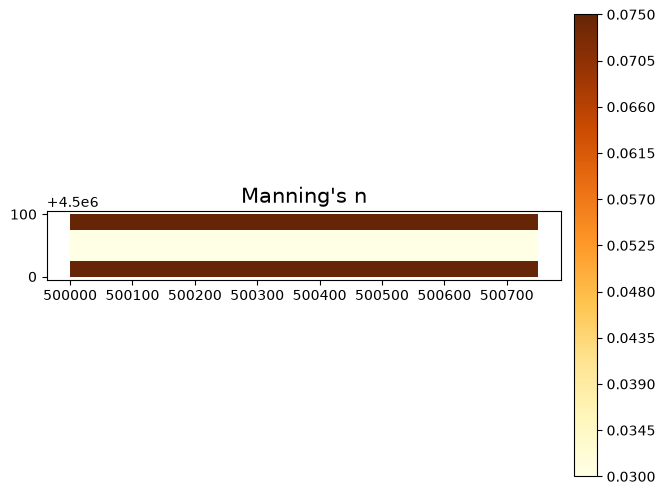

In [10]:
_g = ds.plot('manning_n', cmap='YlOrBr', colorbar=True, title="Manning's n")

### Bed elevation — `node_z`

`node_z` is the terrain the flow runs over (per node, from the `ZB` column). It shows the channel cross-section and the downstream slope.

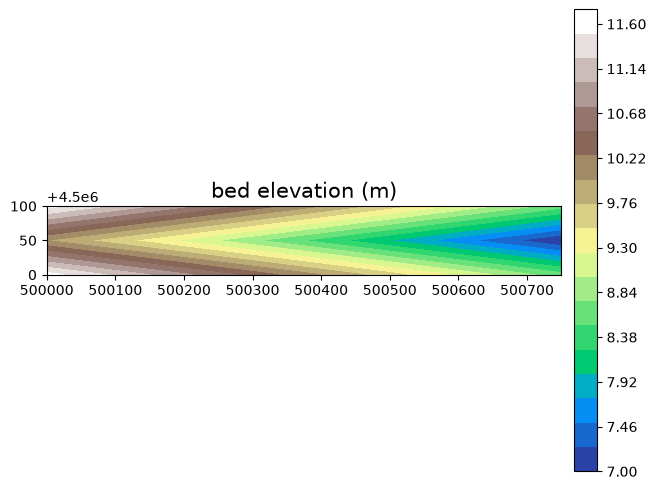

In [11]:
_g = ds.plot('node_z', cmap='terrain', colorbar=True, title='bed elevation (m)')

### Initial water surface — `init_wse`

`init_wse` (the element `ELINITWSE` column) is the model's initial water-surface elevation. In this sample an upstream pool is ponded and the rest is dry (`0`), so the map reads as a filled reach at the inlet.

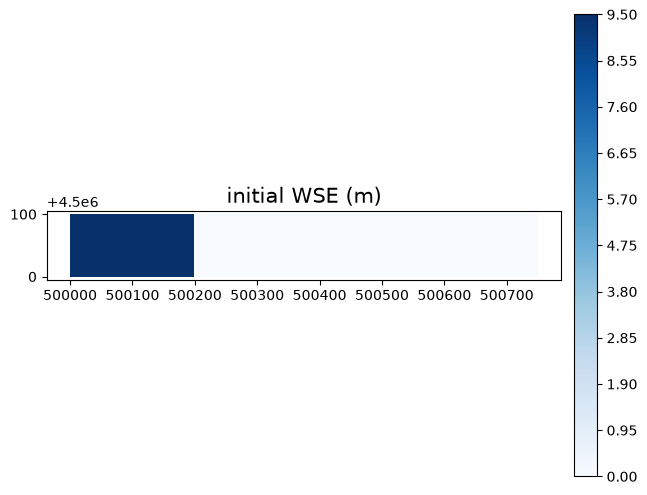

In [12]:
_g = ds.plot('init_wse', cmap='Blues', colorbar=True, title='initial WSE (m)')

### Erodible floor — `min_erode_elev` and the `-9999` sentinel

`min_erode_elev` (the `ELMINERODELEV` column) is the lowest bed a cell may erode to. RiverFlow2D marks *no limit* with `-9999`, which the driver records as the variable's `nodata`. Only the channel cells carry a real floor here; the floodplain cells are all sentinel.

In [13]:
me = ds['min_erode_elev']
print('nodata        :', me.nodata)
print('sentinel faces:', int((me.data == me.nodata).sum()), 'of', me.data.size)

nodata        : -9999.0
sentinel faces: 60 of 120


## 9. Triangle-only geometry — `circumcenters()`

Because a `.FED` is purely triangular, operations defined only for triangle meshes work directly. `circumcenters()` returns the circumscribed-circle centre of every face — the basis of a Voronoi dual. (On a mixed tri/quad mesh this raises; here it just works.)

circumcenters shape: (120, 2)


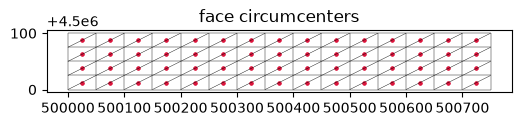

In [14]:
cc = ds.circumcenters()
print('circumcenters shape:', cc.shape)
ax = plt.subplots(figsize=(6, 3))[1]
ds.plot_outline(ax=ax)
ax.scatter(cc[:, 0], cc[:, 1], s=4, color='crimson')
ax.set_title('face circumcenters')
ax.set_aspect('equal')

## 10. It is a first-class `pyramids` object

A `MeshDataset` carries the full geospatial toolkit — no conversion step. A few operations, each visualised or checked.

### 10a. Faces as polygons — `to_geodataframe()`

Every triangle becomes a shapely polygon in a GeoPandas `GeoDataFrame`, ready for a spatial join, overlay or export to any OGR vector format.

,geometry
0,"POLYGON ((500000 4500000, 500050 4500000, 5000..."
1,"POLYGON ((500000 4500000, 500050 4500025, 5000..."
2,"POLYGON ((500050 4500000, 500100 4500000, 5001..."
3,"POLYGON ((500050 4500000, 500100 4500025, 5000..."
4,"POLYGON ((500100 4500000, 500150 4500000, 5001..."


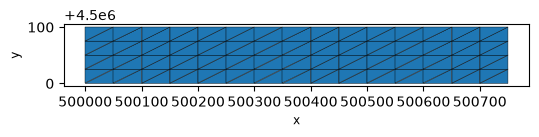

In [15]:
gdf = ds.to_geodataframe()
ax = gdf.plot(edgecolor='k', linewidth=0.3, figsize=(6, 3))
ax.set_aspect('equal')
gdf.head()

### 10b. Outer boundary — `bounding_polygon()`

`bounding_polygon()` dissolves the faces into one shapely polygon tracing the mesh outline, and `exterior_edges()` returns the mesh edges on that boundary.

boundary edges: 38


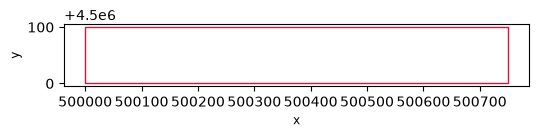

In [16]:
poly = ds.bounding_polygon()
print('boundary edges:', len(ds.exterior_edges()))
ax = gpd.GeoSeries([poly]).plot(facecolor='none', edgecolor='crimson', figsize=(6, 3))
ax.set_aspect('equal')

### 10c. Connectivity — `connected_components()`

`connected_components()` labels each face by the connected sub-mesh it belongs to. One unique label means the mesh is a single watertight piece.

In [17]:
comp = ds.connected_components()
print('faces:', comp.size, ' components:', len(np.unique(comp)))

faces: 120  components: 1


### 10d. Round-trip through UGRID NetCDF — `to_file()`

`to_file(..., driver='ugrid')` writes the mesh to the CF/UGRID NetCDF convention — the lossless format every tool in the stack reads back. We write, re-read and confirm the topology survived.

In [18]:
import tempfile
out = Path(tempfile.mkdtemp()) / 'roundtrip.nc'
ds.to_file(out, driver='ugrid')
back = MeshDataset.read_file(out, driver='ugrid')
print('re-read nodes/faces:', back.n_node, back.n_face)

re-read nodes/faces: 80 120


> **Note — xarray interop.** pyramids-core exposes a `to_xarray()` bridge, but these notebooks deliberately stay within pyramids-core's own GDAL-based UGRID I/O and do not use xarray.

## 11. Takeaway

The `riverflow2d` driver reads a single `.FED` file into a real `MeshDataset`: triangular topology, `node_z` bed elevation, and the element fields `manning_n`, `init_wse` and `min_erode_elev` (with `-9999` honoured as nodata). Being purely triangular, it supports every pyramids operation including the triangle-only ones — map, vectorise, boundary, components, circumcenters and a lossless UGRID round-trip, all with no GIS logic in the driver itself.